# 20 · Coherencia wavelet entre SSN, ICEN y ONI
Greta Solange Díaz Vega · Seminario de Tesis II · UNI

Análisis exploratorio de coherencia cuadrática con wavelet Morlet entre 1,5 y 16 años. Los colores más claros indican mayor coherencia local; las áreas blancas corresponden a bordes excluidos. El máximo descriptivo no equivale a una prueba de significancia o causalidad.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/gretadive/correlacion_actividad_solar_elnino/751cd7c187616d8b7ed7b175280dc80a4e999a29/data/processed/dataset_integrado_precipitacion.csv"
archivo = Path("datos.csv")
df = pd.read_csv(archivo if archivo.exists() else url, parse_dates=["fecha"])
df = df.set_index("fecha").sort_index().asfreq("MS")
variables = ["ICEN", "ONI", "precipitacion_mm"]
assert len(df) == 917 and df[variables + ["SSN"]].notna().all().all()
desfases = [0, 3, 6, 12, 24]

horizontes = [3,6,12,24]
numero = 20
print(df.index.min().date(), df.index.max().date(), len(df), "meses")

1950-01-01 2026-05-01 917 meses


## Análisis

        periodo_anios  coherencia_media  meses_interiores
indice                                                   
ICEN            5.381             0.544             739.0
ONI            10.989             0.673             555.0


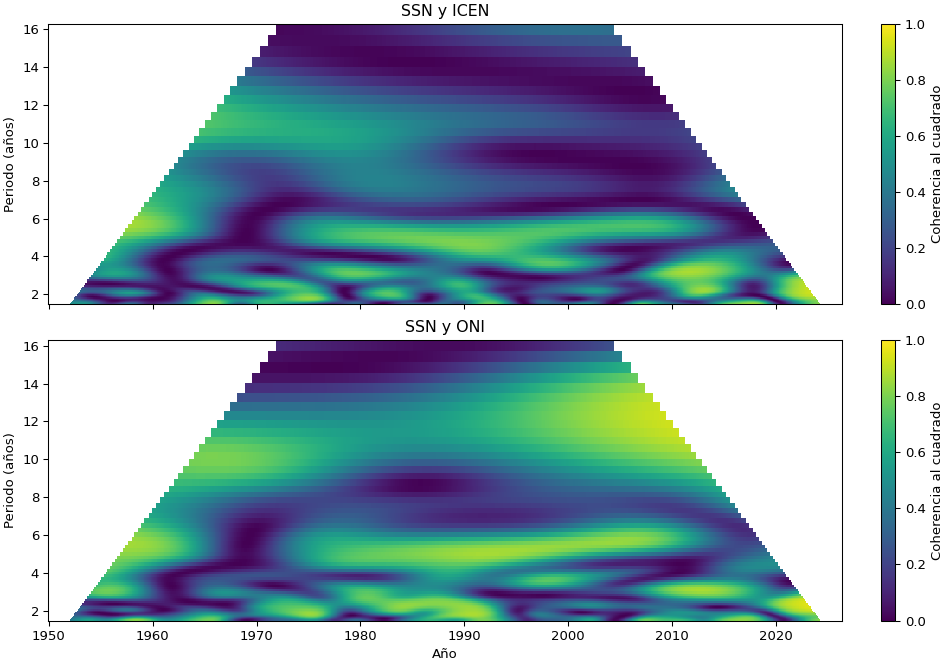

In [2]:
from scipy.signal import detrend, fftconvolve
from scipy.ndimage import gaussian_filter1d
periodos = np.geomspace(1.5,16,64)
escalas = periodos*12*(6+np.sqrt(38))/(4*np.pi)
def morlet(serie):
    x = detrend(np.asarray(serie))
    x = x/x.std()
    filas = []
    for a in escalas:
        t = np.arange(-np.ceil(5*a),np.ceil(5*a)+1)/a
        onda = np.exp(6j*t-t*t/2)/np.sqrt(a)
        filas.append(fftconvolve(x,np.conj(onda[::-1]),mode="same"))
    return np.array(filas)

def suavizar(potencia):
    # Suavizado en tiempo proporcional a la escala y en log-periodo.
    temporal = np.array([gaussian_filter1d(f/a,a,mode="nearest") for f,a in zip(potencia,escalas)])
    return gaussian_filter1d(temporal,2,axis=0,mode="nearest")

sol = morlet(df.SSN)
pot_sol = suavizar(abs(sol)**2)
fig, ejes = plt.subplots(2,1,figsize=(10,7),layout="constrained",sharex=True)
resumen = []
for ax,indice in zip(ejes,["ICEN","ONI"]):
    clima = morlet(df[indice])
    cruzada = suavizar(sol*np.conj(clima))
    r2 = np.clip(abs(cruzada)**2/(pot_sol*suavizar(abs(clima)**2)),0,1)
    distancia = np.minimum(np.arange(len(df)),np.arange(len(df))[::-1])
    r2[distancia[None,:] < np.sqrt(2)*escalas[:,None]] = np.nan
    imagen = ax.pcolormesh(df.index,periodos,r2,vmin=0,vmax=1,shading="auto",cmap="viridis")
    ax.set(title="SSN y "+indice,ylabel="Periodo (años)")
    fig.colorbar(imagen,ax=ax,label="Coherencia al cuadrado")
    for i,p in enumerate(periodos):
        resumen.append([indice,p,np.nanmean(r2[i]),np.isfinite(r2[i]).sum()])
ejes[-1].set_xlabel("Año")
fig.savefig("20_coherencia.png",dpi=180)
plt.show()
tabla = pd.DataFrame(resumen,columns=["indice","periodo_anios","coherencia_media","meses_interiores"])
tabla.to_csv("20_coherencia_por_periodo.csv",index=False)
print(tabla.groupby("indice").apply(lambda g:g.loc[g.coherencia_media.idxmax()],include_groups=False).round(3))
